In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
np.random.seed(42)

dates = pd.date_range(
    start='2023-01-01',
    periods=36,
    freq='MS'
)

sales = (
    50000
    + np.arange(36) * 1500
    + np.random.randint(-5000, 5000, 36)
)

df = pd.DataFrame({
    'Date': dates,
    'Sales': sales
})

print("Retail Sales Dataset Created Successfully!")

display(df.head(10))

Retail Sales Dataset Created Successfully!


,Date,Sales
0,2023-01-01,52270
1,2023-02-01,47360
2,2023-03-01,53390
3,2023-04-01,54691
4,2023-05-01,56734
5,2023-06-01,58765
6,2023-07-01,54466
7,2023-08-01,59926
8,2023-09-01,62578
9,2023-10-01,66822


In [3]:
df.to_csv('retail_sales.csv', index=False)

print("Sales dataset saved successfully!")

Sales dataset saved successfully!


In [4]:
df = pd.read_csv('retail_sales.csv')

display(df.head())

,Date,Sales
0,2023-01-01,52270
1,2023-02-01,47360
2,2023-03-01,53390
3,2023-04-01,54691
4,2023-05-01,56734


In [5]:
print("Dataset Information:")

df.info()

print("\nStatistical Summary:")

display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Date    36 non-null     str  
 1   Sales   36 non-null     int64
dtypes: int64(1), str(1)
memory usage: 708.0 bytes

Statistical Summary:


,Sales
count,36.000000
mean,75900.888889
std,15986.904260
min,47360.000000
25%,62123.000000
50%,75987.500000
75%,88729.000000
max,103734.000000


In [6]:
df['Date'] = pd.to_datetime(df['Date'])

print(df.dtypes)

Date     datetime64[us]
Sales             int64
dtype: object


In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Date     0
Sales    0
dtype: int64


In [8]:
df = df.drop_duplicates()

print("Duplicate records removed!")
print("Total records:", len(df))

Duplicate records removed!
Total records: 36


In [9]:
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year

display(df.head(10))

,Date,Sales,Month,Year
0,2023-01-01,52270,1,2023
1,2023-02-01,47360,2,2023
2,2023-03-01,53390,3,2023
3,2023-04-01,54691,4,2023
4,2023-05-01,56734,5,2023
5,2023-06-01,58765,6,2023
6,2023-07-01,54466,7,2023
7,2023-08-01,59926,8,2023
8,2023-09-01,62578,9,2023
9,2023-10-01,66822,10,2023


In [10]:
print("Average Monthly Sales:", df['Sales'].mean())

print("Highest Monthly Sales:", df['Sales'].max())

print("Lowest Monthly Sales:", df['Sales'].min())

print("Standard Deviation:", df['Sales'].std())

Average Monthly Sales: 75900.88888888889
Highest Monthly Sales: 103734
Lowest Monthly Sales: 47360
Standard Deviation: 15986.904259920777


In [11]:
result = stats.linregress(
    range(len(df)),
    df['Sales']
)

print("Sales Trend Analysis")
print("Slope:", round(result.slope, 2))
print("Correlation:", round(result.rvalue, 3))
print("P-value:", round(result.pvalue, 4))

if result.slope > 0:
    print("Sales are increasing.")
else:
    print("Sales are decreasing.")

Sales Trend Analysis
Slope: 1493.61
Correlation: 0.984
P-value: 0.0
Sales are increasing.


In [12]:
z_scores = np.abs(stats.zscore(df['Sales']))

outliers = df[z_scores > 2]

print("Unusual Sales Records:")
display(outliers)

Unusual Sales Records:


,Date,Sales,Month,Year


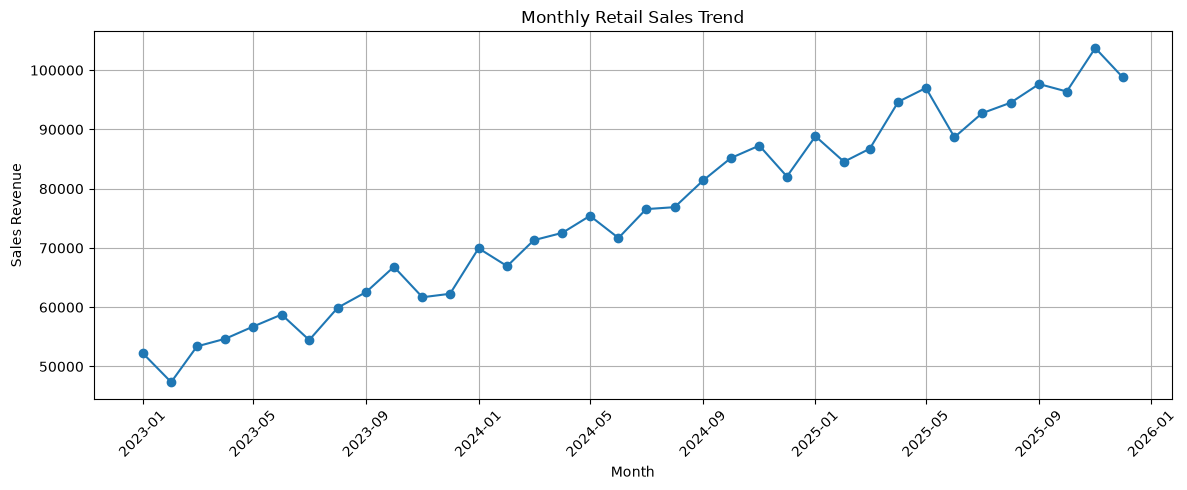

In [13]:
plt.figure(figsize=(12, 5))

plt.plot(
    df['Date'],
    df['Sales'],
    marker='o'
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Revenue")

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

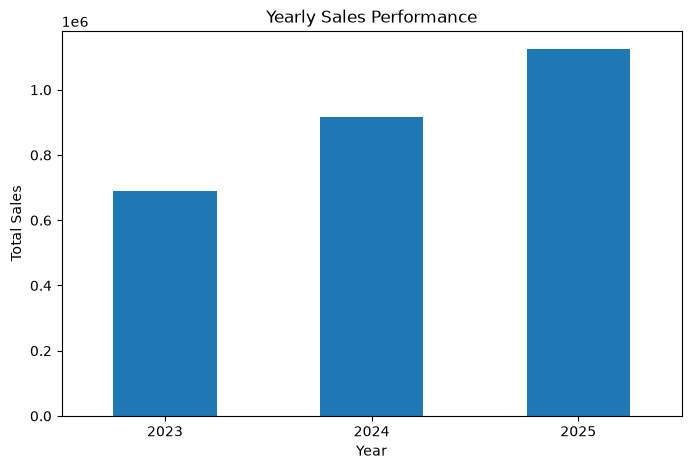

In [14]:
yearly_sales = df.groupby('Year')['Sales'].sum()

plt.figure(figsize=(8, 5))

yearly_sales.plot(kind='bar')

plt.title("Yearly Sales Performance")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.show()

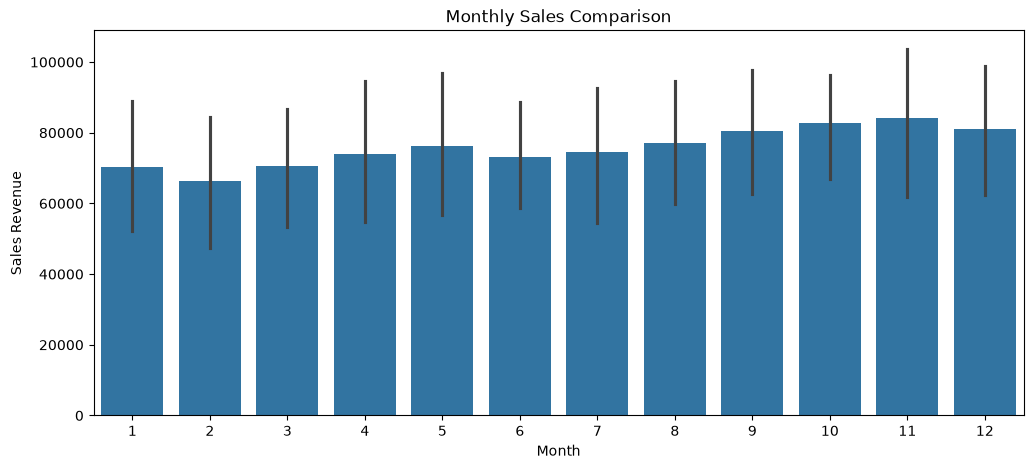

In [15]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=df,
    x='Month',
    y='Sales'
)

plt.title("Monthly Sales Comparison")
plt.xlabel("Month")
plt.ylabel("Sales Revenue")

plt.show()

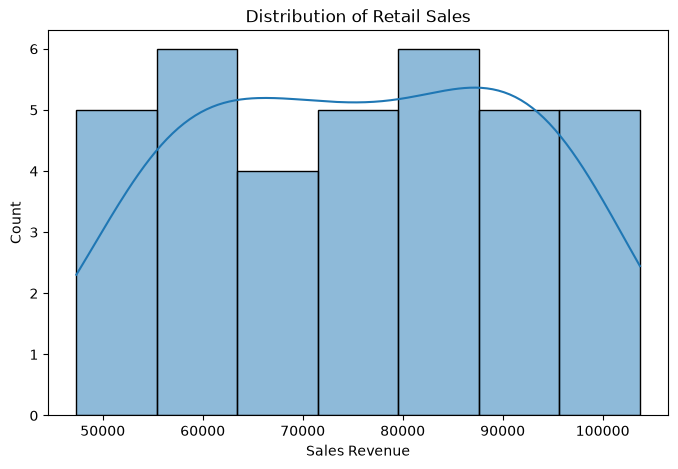

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Sales',
    kde=True
)

plt.title("Distribution of Retail Sales")
plt.xlabel("Sales Revenue")

plt.show()

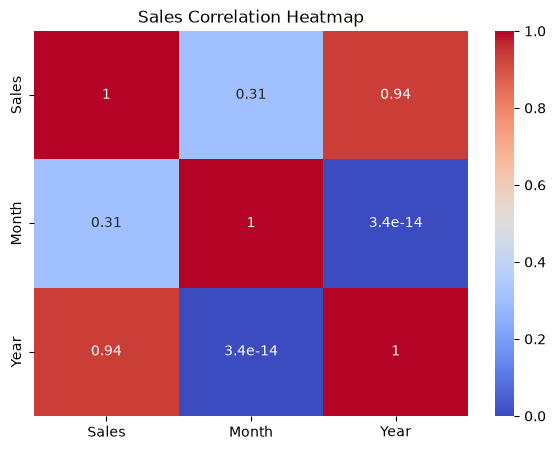

In [17]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    df[['Sales', 'Month', 'Year']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Sales Correlation Heatmap")
plt.show()

In [19]:
df = df.sort_values('Date').reset_index(drop=True)

df['Time'] = np.arange(len(df))

month_features = pd.get_dummies(
    df['Month'],
    prefix='Month',
    drop_first=True,
    dtype=int
)

X = pd.concat(
    [df[['Time']], month_features],
    axis=1
)

y = df['Sales']

In [20]:
X_train = X.iloc[:30]
X_test = X.iloc[30:]

y_train = y.iloc[:30]
y_test = y.iloc[30:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 30
Testing records: 6


In [21]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [22]:
predictions = model.predict(X_test)

results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': predictions.round(2)
})

display(results)

,Actual Sales,Predicted Sales
0,92734,93318.6
1,94505,96213.6
2,97658,99795.1
3,96399,103802.1
4,103734,102287.6
5,98767,99971.6


In [23]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("Model Evaluation")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

Model Evaluation
MAE: 2414.07
RMSE: 3321.08
R2 Score: 0.1


In [24]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("Model Evaluation")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 2))

Model Evaluation
MAE: 2414.07
RMSE: 3321.08
R2 Score: 0.1


In [25]:
future_dates = pd.date_range(
    start=df['Date'].max() + pd.offsets.MonthBegin(1),
    periods=6,
    freq='MS'
)

future_df = pd.DataFrame({
    'Date': future_dates
})

future_df['Time'] = np.arange(
    len(df), len(df) + 6
)

future_month_features = pd.get_dummies(
    future_df['Date'].dt.month,
    prefix='Month',
    drop_first=True,
    dtype=int
)

future_X = pd.concat(
    [future_df[['Time']], future_month_features],
    axis=1
)

future_X = future_X.reindex(
    columns=X.columns,
    fill_value=0
)

future_predictions = model.predict(future_X)

future_df['Predicted Sales'] = future_predictions.round(2)

display(future_df)

,Date,Time,Predicted Sales
0,2026-01-01,36,107433.47
1,2026-02-01,37,103357.47
2,2026-03-01,38,107560.13
3,2026-04-01,39,111047.13
4,2026-05-01,40,113461.47
5,2026-06-01,41,110123.47


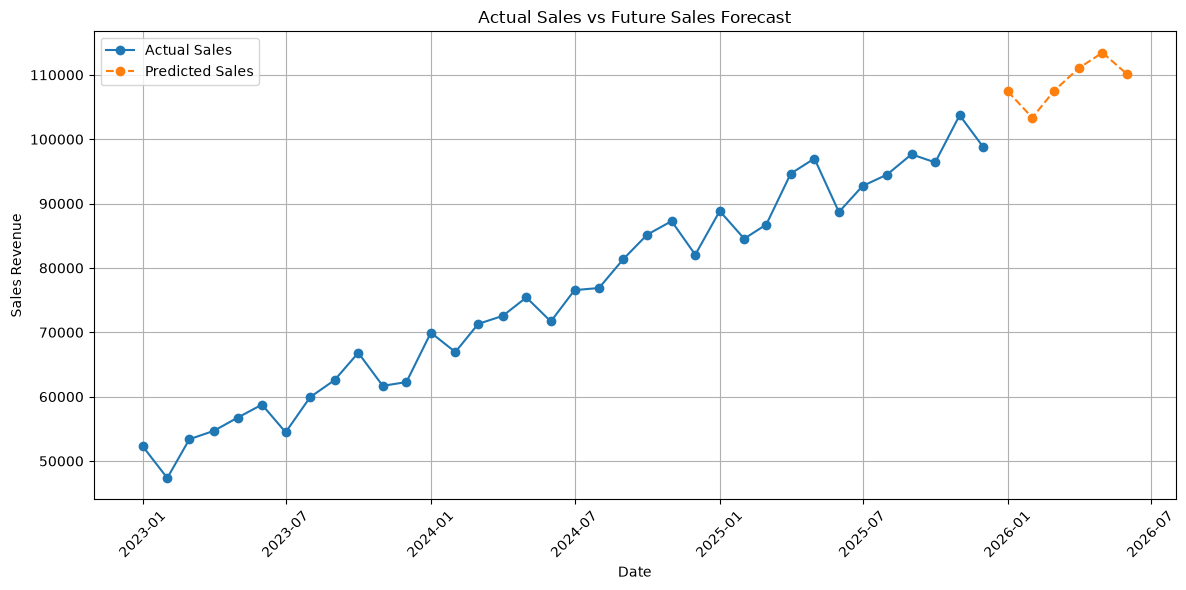

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(
    df['Date'],
    df['Sales'],
    label='Actual Sales',
    marker='o'
)

plt.plot(
    future_df['Date'],
    future_df['Predicted Sales'],
    label='Predicted Sales',
    marker='o',
    linestyle='--'
)

plt.title("Actual Sales vs Future Sales Forecast")

plt.xlabel("Date")
plt.ylabel("Sales Revenue")

plt.legend()
plt.grid()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
print("========== SALES FORECASTING DASHBOARD ==========")

print("Total Sales:", df['Sales'].sum())

print("Average Monthly Sales:", round(df['Sales'].mean(), 2))

print("Highest Sales:", df['Sales'].max())

print("Lowest Sales:", df['Sales'].min())

print("Next 6 Months Predicted Sales:",
      round(future_df['Predicted Sales'].sum(), 2))

print("=================================================")

========== SALES FORECASTING DASHBOARD ==========
Total Sales: 2732432
Average Monthly Sales: 75900.89
Highest Sales: 103734
Lowest Sales: 47360
Next 6 Months Predicted Sales: 652983.14


In [28]:
future_df.to_csv(
    'future_sales_forecast.csv',
    index=False
)

print("Future sales forecast saved successfully!")

Future sales forecast saved successfully!
